In [1]:
import torch
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from torch import nn



In [2]:
image = torch.zeros(3,224,224)
print("Form:",image.shape)
print("nombre de valeur:",image.numel())

Form: torch.Size([3, 224, 224])
nombre de valeur: 150528


In [3]:
data_dir = Path("data/hymenoptera_data")
print("Dossier trouvé :", data_dir.exists())
print("Dossier train trouvé :", (data_dir / "train").exists())
print("Dossier val trouvé :", (data_dir / "val").exists())

Dossier trouvé : True
Dossier train trouvé : True
Dossier val trouvé : True


Taille (largeur, hauteur) : (768, 512)


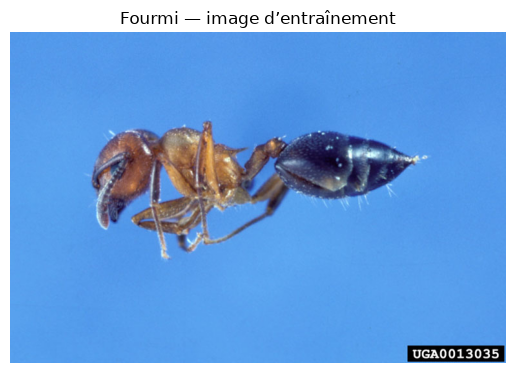

In [4]:
image_path = sorted ((data_dir/"train"/"ants").glob("*.jpg"))[0]
img = Image.open(image_path).convert("RGB")
print("Taille (largeur, hauteur) :", img.size)

plt.imshow(img)
plt.title("Fourmi — image d’entraînement")
plt.axis("off")
plt.show()

Taille (largeur, hauteur) : (500, 333)


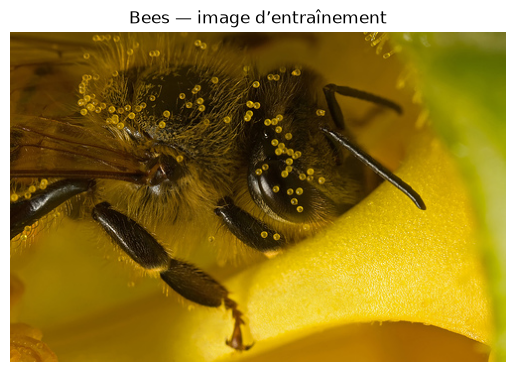

In [5]:
image_path2 = sorted ((data_dir/"train"/"bees").glob("*.jpg"))[0]
img2 = Image.open(image_path2).convert("RGB")
print("Taille (largeur, hauteur) :", img2.size)

plt.imshow(img2)
plt.title("Bees — image d’entraînement")
plt.axis("off")
plt.show()

In [6]:
to_tensor = transforms.ToTensor()
image_tensor = to_tensor(img2)
print ("Forme :",image_tensor.shape)
print("Type :", image_tensor.dtype)
print("Minimum :", image_tensor.min().item())
print("Maximum :", image_tensor.max().item())

Forme : torch.Size([3, 333, 500])
Type : torch.float32
Minimum : 0.0
Maximum : 1.0


In [7]:
# preprocess prépare l'image : redimensionnement, recadrage en 224×224,
# puis conversion en tenseur. preprocess(img2) applique ces étapes à img2.
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),#garde un carré de 224 × 224 pixels au centre de l’image et retire les bords.
    transforms.ToTensor()
])
prepared_image = preprocess(img2)# tenseur
print("Form apres preparation:", prepared_image.shape)

Form apres preparation: torch.Size([3, 224, 224])


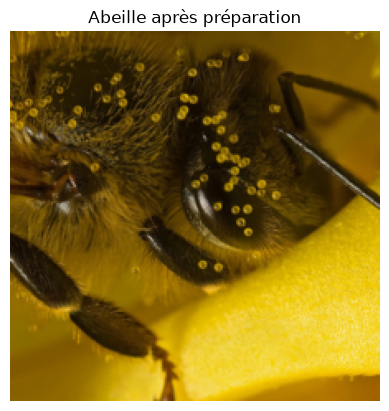

In [8]:
plt.imshow(prepared_image.permute(1, 2, 0))# pour réorganiser les axes 
plt.title("Abeille après préparation")
plt.axis("off")
plt.show()

In [9]:
train_dataset = datasets.ImageFolder(
    root = data_dir / "train",#indique où chercher les images
    transform = preprocess #indique comment préparer chaque image
)

print("Catégories :", train_dataset.classes)
print("Étiquettes :", train_dataset.class_to_idx)
print("Nombre d'images :", len(train_dataset))

Catégories : ['ants', 'bees']
Étiquettes : {'ants': 0, 'bees': 1}
Nombre d'images : 244


In [10]:
val_dataset = datasets.ImageFolder(
    root = data_dir / "val",#indique où chercher les images
    transform = preprocess #indique comment préparer chaque image
)

print("Étiquettes :", val_dataset.class_to_idx)
print("Nombre d'images de validation :", len(val_dataset))

Étiquettes : {'ants': 0, 'bees': 1}
Nombre d'images de validation : 153


In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle= False
)

images, labels = next(iter(train_loader)) #iter(train_loader) permet de parcourir les lots
print("Forme des images :", images.shape)
print("Forme des étiquettes :", labels.shape)

Forme des images : torch.Size([16, 3, 224, 224])
Forme des étiquettes : torch.Size([16])


In [12]:
model_preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
train_dataset.transform = model_preprocess
val_dataset.transform = model_preprocess
images, labels = next(iter(train_loader))

print("Forme :", images.shape)
print("Minimum :", images.min().item())
print("Maximum :", images.max().item())

Forme : torch.Size([16, 3, 224, 224])
Minimum : -2.1179039478302
Maximum : 2.640000104904175


In [13]:
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

In [14]:
print(model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [15]:
#gèle les paramètres existants
for param in model.parameters():
    param.requires_grad = False

In [16]:
#remplace la dernière couche
model.fc = nn.Linear(model.fc.in_features,2)
print(model.fc)

Linear(in_features=512, out_features=2, bias=True)


In [17]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [18]:
model.eval()
images, labels = next (iter(train_loader))
optimizer.zero_grad()
outputs = model(images)
loss=criterion(outputs,labels)
loss.backward()
optimizer.step()

print("Forme des scores :", outputs.shape)
print("Perte :", loss.item())

Forme des scores : torch.Size([16, 2])
Perte : 0.6348282694816589


In [19]:
# Garder les statistiques des couches préentraînées fixes
model.eval()

total_loss = 0.0
total_images = 0

for images, labels in train_loader:
    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = images.size(0)
    total_loss += loss.item() * batch_size
    total_images += batch_size

epoch_loss = total_loss / total_images

print("Nombre d'images traitées :", total_images)
print("Perte moyenne :", epoch_loss)

Nombre d'images traitées : 244
Perte moyenne : 0.3589095756655834


In [20]:
model.eval()

val_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        val_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += images.size(0)

print("Perte de validation :", val_loss / total)
print("Accuracy de validation :", 100 * correct / total, "%")

Perte de validation : 0.27301424761223636
Accuracy de validation : 92.81045751633987 %


In [21]:
import copy

best_accuracy = correct / total
best_model_weights = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [epoch_loss],
    "val_loss": [val_loss / total],
    "val_accuracy": [best_accuracy]
}

In [22]:
num_epochs = 5
start_epoch = len(history["train_loss"])

for epoch in range(num_epochs):
    # 1. Entraînement de la dernière couche
    model.eval()
    total_loss = 0.0
    total_images = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

    train_loss = total_loss / total_images

    # 2. Validation sans ajuster les paramètres
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(dim=1)

            val_loss += loss.item() * images.size(0)
            correct += (predictions == labels).sum().item()
            total += images.size(0)

    validation_loss = val_loss / total
    validation_accuracy = correct / total

    # 3. Conserver les résultats pour les courbes
    history["train_loss"].append(train_loss)
    history["val_loss"].append(validation_loss)
    history["val_accuracy"].append(validation_accuracy)

    # 4. Garder une copie du meilleur modèle
    if validation_accuracy > best_accuracy:
        best_accuracy = validation_accuracy
        best_model_weights = copy.deepcopy(model.state_dict())

    print(
        f"Époque {start_epoch + epoch + 1} | "
        f"Train loss : {train_loss:.4f} | "
        f"Val loss : {validation_loss:.4f} | "
        f"Val accuracy : {validation_accuracy:.2%}"
    )

Époque 2 | Train loss : 0.1808 | Val loss : 0.1885 | Val accuracy : 94.12%
Époque 3 | Train loss : 0.1310 | Val loss : 0.1659 | Val accuracy : 95.42%
Époque 4 | Train loss : 0.1039 | Val loss : 0.1575 | Val accuracy : 95.42%
Époque 5 | Train loss : 0.0915 | Val loss : 0.1438 | Val accuracy : 96.08%
Époque 6 | Train loss : 0.0738 | Val loss : 0.1481 | Val accuracy : 95.42%


In [23]:
model.load_state_dict(best_model_weights)
model.eval()

print(f"Meilleure accuracy de validation : {best_accuracy:.2%}")

Meilleure accuracy de validation : 96.08%


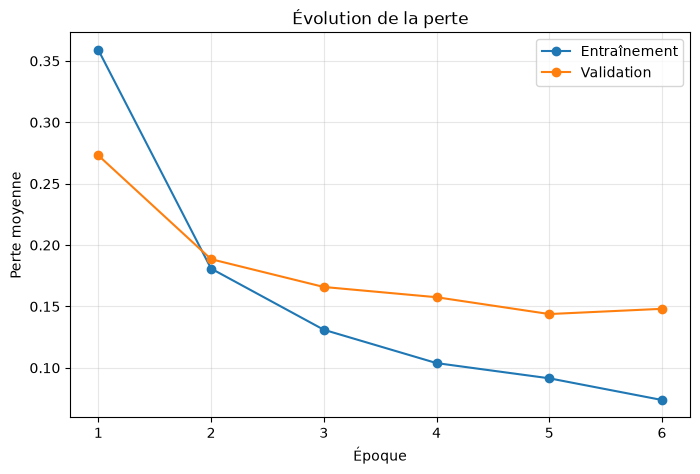

In [24]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="Entraînement")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")

plt.xlabel("Époque")
plt.ylabel("Perte moyenne")
plt.title("Évolution de la perte")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.tolist())

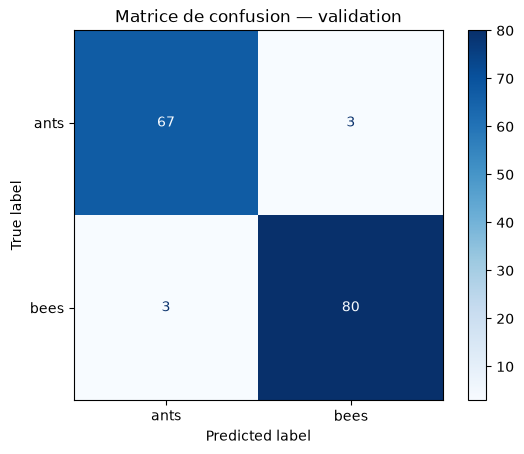

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=val_dataset.classes
)

display.plot(cmap="Blues")
plt.title("Matrice de confusion — validation")
plt.show()

In [27]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=val_dataset.classes,
    digits=3
))

              precision    recall  f1-score   support

        ants      0.957     0.957     0.957        70
        bees      0.964     0.964     0.964        83

    accuracy                          0.961       153
   macro avg      0.960     0.960     0.960       153
weighted avg      0.961     0.961     0.961       153



In [28]:
error_indices = [
    i
    for i, (true, pred) in enumerate(zip(all_labels, all_predictions))
    if true != pred
]

print("Nombre d'erreurs :", len(error_indices))

Nombre d'erreurs : 6


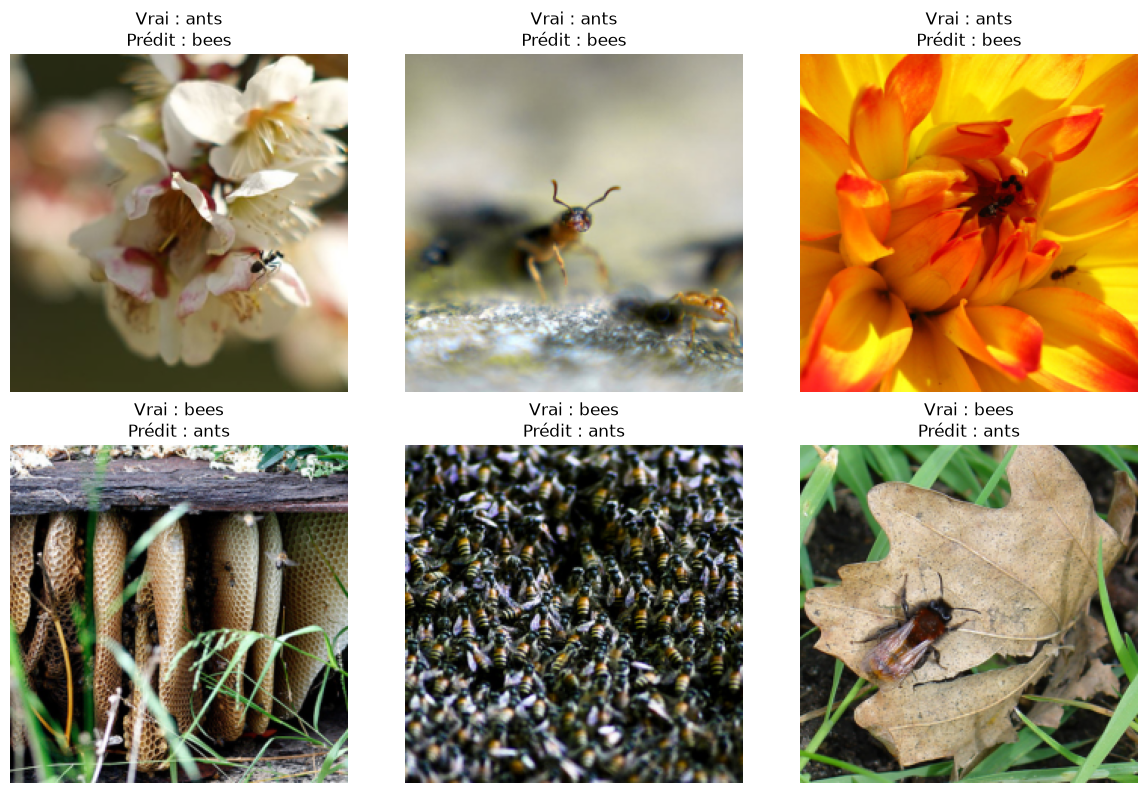

In [29]:
# Valeurs utilisées pour la normalisation
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, index in zip(axes.flat, error_indices):
    image, label = val_dataset[index]
    prediction = all_predictions[index]

    # Annuler la normalisation pour retrouver les couleurs
    image = (image * std + mean).clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(
        f"Vrai : {val_dataset.classes[label]}\n"
        f"Prédit : {val_dataset.classes[prediction]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

torch.save(
    {
        "model_state_dict": best_model_weights,
        "class_to_idx": train_dataset.class_to_idx,
        "best_val_accuracy": best_accuracy
    },
    model_dir / "resnet18_ants_bees.pth"
)

print("Modèle sauvegardé !")

Modèle sauvegardé !


In [31]:
checkpoint = torch.load(
    "models/resnet18_ants_bees.pth",
    map_location="cpu",
    weights_only=True
)

loaded_model = models.resnet18(weights=None)
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, 2)

loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

idx_to_class = {
    index: name
    for name, index in checkpoint["class_to_idx"].items()
}

print("Modèle rechargé !")
print("Catégories :", idx_to_class)

Modèle rechargé !
Catégories : {0: 'ants', 1: 'bees'}


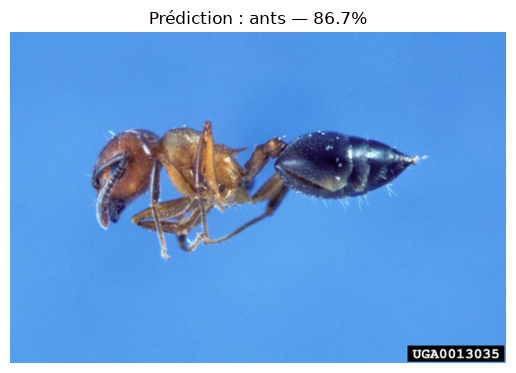

In [34]:
from PIL import Image

image_path = "test_images/abeille.jpg"
image_path = r"C:\Users\jamal\Downloads\dmytro-koplyk-albwSHfRMLc-unsplash.jpg"
image_tensor = model_preprocess(img).unsqueeze(0)

with torch.no_grad():
    outputs = loaded_model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)

    predicted_index = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_index].item()

predicted_class = idx_to_class[predicted_index]

plt.imshow(img)
plt.title(f"Prédiction : {predicted_class} — {confidence:.1%}")
plt.axis("off")
plt.show()

In [33]:
from pathlib import Path

print("Dossier de travail :", Path.cwd())
print("Images disponibles :", list(Path("test_images").glob("*")))

Dossier de travail : c:\Users\jamal\OneDrive\Desktop\projects\Image Classification
Images disponibles : []


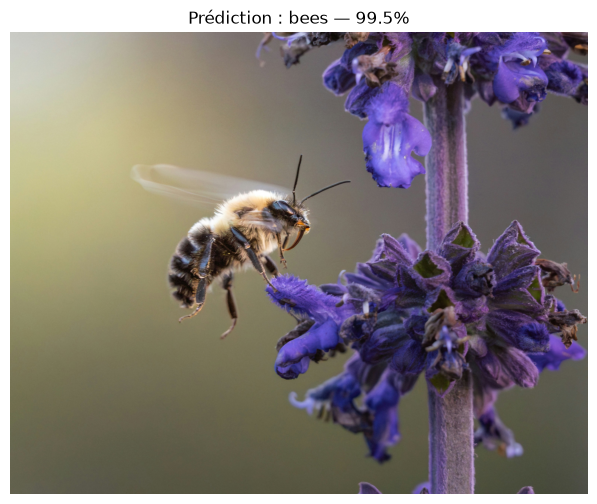

In [35]:
new_image_path = r"C:\Users\jamal\Downloads\dmytro-koplyk-albwSHfRMLc-unsplash.jpg"

new_img = Image.open(new_image_path).convert("RGB")
new_tensor = model_preprocess(new_img).unsqueeze(0)

loaded_model.eval()

with torch.no_grad():
    new_outputs = loaded_model(new_tensor)
    new_probs = torch.softmax(new_outputs, dim=1)
    new_index = new_probs.argmax(dim=1).item()
    new_confidence = new_probs[0, new_index].item()

plt.figure(figsize=(8, 6))
plt.imshow(new_img)
plt.title(
    f"Prédiction : {idx_to_class[new_index]} — {new_confidence:.1%}"
)
plt.axis("off")
plt.show()